## 0. Окружение и сохранение

In [1]:
import os, json, time, math, random, hashlib, platform, shutil, warnings
from pathlib import Path
from dataclasses import dataclass, asdict, replace
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, transforms
from IPython.display import display

assert torch.cuda.is_available(), 'Нужна GPU: Runtime → Change runtime type → T4 GPU'
DEVICE = torch.device('cuda')
print('GPU:', torch.cuda.get_device_name(0),'Torch:',torch.__version__,'Torchvision:', torchvision.__version__)
USE_DRIVE = True
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        ROOT = Path('/content/drive/MyDrive/itmo_hw2_superconvergence')
    except ImportError:
        ROOT = Path('/mnt/data/itmo_hw2_superconvergence')
        print('Не Colab: локальное сохранение', ROOT)
else:
    ROOT = Path('/content/itmo_hw2_superconvergence')
DATA = Path('/content/hw2_data') if Path('/content').exists() else ROOT/'datasets'
for p in [ROOT, ROOT/'runs',ROOT/'figures',ROOT/'exports',DATA]: p.mkdir(parents=True, exist_ok=True)
PLT_DPI=175
RUN_LONG_EXPERIMENTS=False  # долгие запуски только после просмотра оценки времени
print('Артефакты:', ROOT)
json.dump({'torch':torch.__version__,'torchvision':torchvision.__version__,'gpu':torch.cuda.get_device_name(0),'platform':platform.platform()},open(ROOT/'environment.json','w'),indent=2)


GPU: Tesla T4 Torch: 2.11.0+cu130 Torchvision: 0.26.0+cu130
Mounted at /content/drive
Артефакты: /content/drive/MyDrive/itmo_hw2_superconvergence


## 1. Данные, модели и параметры

In [2]:
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def make_loaders(dataset, batch_size, seed, subset_size=None, workers=2, augmentation=True):
    if dataset=='mnist':
        tf_train=transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.1307,),(0.3081,))])
        tf_test=tf_train; klass=datasets.MNIST
    elif dataset in ('cifar10','cifar100'):
        norm=transforms.Normalize((0.4914,0.4822,0.4465),(0.2470,0.2435,0.2616)) if dataset=='cifar10' else transforms.Normalize((0.5071,0.4867,0.4408),(0.2675,0.2565,0.2761))
        prep=([transforms.RandomCrop(32,padding=4),transforms.RandomHorizontalFlip()] if augmentation else [])
        tf_train=transforms.Compose(prep+[transforms.ToTensor(),norm]); tf_test=transforms.Compose([transforms.ToTensor(),norm])
        klass=datasets.CIFAR10 if dataset=='cifar10' else datasets.CIFAR100
    else: raise ValueError(dataset)
    train=klass(str(DATA),train=True,download=True,transform=tf_train)
    test=klass(str(DATA),train=False,download=True,transform=tf_test)
    if subset_size:
        labels=np.asarray(train.targets)
        rng=np.random.default_rng(seed)
        classes=np.unique(labels); n=subset_size//len(classes)
        ix=np.concatenate([rng.choice(np.flatnonzero(labels==cl),n,replace=False) for cl in classes])
        if len(ix)<subset_size:
            extra=rng.choice(np.setdiff1d(np.arange(len(labels)),ix),subset_size-len(ix),replace=False)
            ix=np.concatenate([ix,extra])
        ix=np.sort(ix); train=Subset(train,ix)
    generator=torch.Generator().manual_seed(seed)
    def init_worker(wid):
        s=torch.initial_seed()%2**32; np.random.seed(s);random.seed(s)
    common=dict(batch_size=batch_size,num_workers=workers,pin_memory=True,worker_init_fn=init_worker,persistent_workers=bool(workers))
    return (DataLoader(train,shuffle=True,generator=generator,**common),
            DataLoader(test,shuffle=False,**common))

class LeNet(nn.Module):
    # Caffe LeNet: Conv(20,5)→Pool→Conv(50,5)→Pool→FC500→FC10
    def __init__(self):
        super().__init__()
        self.conv1=nn.Conv2d(1,20,5); self.conv2=nn.Conv2d(20,50,5)
        self.fc1=nn.Linear(50*4*4,500);self.fc2=nn.Linear(500,10)
    def forward(self,x):
        x=F.max_pool2d(F.relu(self.conv1(x)),2)
        x=F.max_pool2d(F.relu(self.conv2(x)),2)
        return self.fc2(F.relu(self.fc1(x.flatten(1))))

class BasicBlock(nn.Module):
    def __init__(self,inc,outc,stride,bn_momentum):
        super().__init__()
        self.conv1=nn.Conv2d(inc,outc,3,stride,1,bias=False)
        self.bn1=nn.BatchNorm2d(outc,momentum=bn_momentum)
        self.conv2=nn.Conv2d(outc,outc,3,1,1,bias=False)
        self.bn2=nn.BatchNorm2d(outc,momentum=bn_momentum)
        self.downsample = (inc!=outc or stride!=1)
        self.stride=stride; self.inc=inc;self.outc=outc
    def forward(self,x):
        y=self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))
        if self.downsample:
            # CIFAR ResNet option A: average-pool downsampling and zero-pad channels
            skip=F.avg_pool2d(x,1,self.stride) if self.stride!=1 else x
            d=self.outc-skip.shape[1]
            if d>0:skip=F.pad(skip,(0,0,0,0,d//2,d-d//2))
        else:skip=x
        return F.relu(y+skip)
class CIFARResNet(nn.Module):
    def __init__(self,depth=20,classes=10,bn_momentum=.05):
        super().__init__(); assert (depth-2)%6==0
        n=(depth-2)//6
        self.stem=nn.Sequential(nn.Conv2d(3,16,3,1,1,bias=False),nn.BatchNorm2d(16,momentum=bn_momentum),nn.ReLU())
        self.blocks=nn.Sequential(*([BasicBlock(16,16,1,bn_momentum)]*0),
            *[BasicBlock(16,16,1,bn_momentum) for _ in range(n)],
            BasicBlock(16,32,2,bn_momentum),
            *[BasicBlock(32,32,1,bn_momentum) for _ in range(n-1)],
            BasicBlock(32,64,2,bn_momentum),
            *[BasicBlock(64,64,1,bn_momentum) for _ in range(n-1)])
        self.fc=nn.Linear(64,classes)
        for m in self.modules():
            if isinstance(m,nn.Conv2d):nn.init.kaiming_normal_(m.weight,mode='fan_out',nonlinearity='relu')
    def forward(self,x):
        x=self.blocks(self.stem(x));return self.fc(F.adaptive_avg_pool2d(x,1).flatten(1))

def build_model(c):
    if c.model=='lenet': return LeNet()
    return CIFARResNet(int(c.model.replace('resnet','')),10 if c.dataset=='cifar10' else 100,c.bn_momentum)

# Shape sanity
for arch in ['lenet','resnet20','resnet56']:
    spec=type('Spec',(),dict(model=arch,dataset='mnist' if arch=='lenet' else 'cifar10',bn_momentum=.05))
    m=build_model(spec); xx=torch.randn(2,1,28,28) if arch=='lenet' else torch.randn(2,3,32,32)
    print(arch, tuple(m(xx).shape),sum(p.numel() for p in m.parameters()),'params')


lenet (2, 10) 431080 params
resnet20 (2, 10) 269722 params
resnet56 (2, 10) 853018 params


In [3]:
@dataclass(frozen=True)
class Exp:
    name:str; dataset:str; model:str; policy:str; epochs:int
    batch_size:int=128; seed:int=42; subset_size:int|None=None
    high_lr:float=.1; low_lr:float=.001; final_lr:float=1e-5
    momentum:float=.9; cycle_momentum:bool=False; momentum_high:float=.95; momentum_low:float=.85
    weight_decay:float=1e-4; bn_momentum:float=.05
    augmentation:bool=True; tail_frac:float=.05
    eval_every:int=1; checkpoint_every:int=1; workers:int=2
    max_steps:int|None=None; amp:bool=False
    milestones:tuple=(.625,.875)

def linear(a,b,t): return a+(b-a)*min(1.,max(0.,t))

def lr_momentum_at(c,step,total):
    f=step/max(total-1,1)
    if c.policy=='constant': lr=c.high_lr
    elif c.policy=='piecewise': lr=c.high_lr*(.1**sum(f>=q for q in c.milestones))
    elif c.policy=='inverse': lr=c.high_lr*(1+0.0001*step)**(-.75)
    elif c.policy in ('triangle','onecycle'):
        active=1.0 if c.policy=='triangle' else (1-c.tail_frac)
        ratio=min(1.,f/active)
        if f>=active and c.policy=='onecycle':
            lr=linear(c.low_lr,c.final_lr,(f-active)/max(1-active,1e-8))
        elif ratio<=.5:lr=linear(c.low_lr,c.high_lr,ratio*2)
        else:lr=linear(c.high_lr,c.low_lr,(ratio-.5)*2)
    else:raise ValueError(c.policy)
    mom=c.momentum
    if c.cycle_momentum and c.policy in ('triangle','onecycle'):
        active=1.0 if c.policy=='triangle' else (1-c.tail_frac)
        ratio=min(1.,f/active)
        mom=linear(c.momentum_high,c.momentum_low,2*ratio) if ratio<=.5 else linear(c.momentum_low,c.momentum_high,2*(ratio-.5))
    return float(lr),float(mom)

def id_for(c):
    blob=json.dumps(asdict(c),sort_keys=True,default=str)
    h=hashlib.sha256(blob.encode()).hexdigest()[:10]
    return c.name+'__'+h

def runpath(c):return ROOT/'runs'/id_for(c)

def plot_schedule(c,steps=1000):
    fig,ax=plt.subplots(figsize=(7,2.8));values=[lr_momentum_at(c,i,steps)[0] for i in range(steps)]
    ax.plot(np.linspace(0,100,steps),values,label='learning rate');ax.set(xlabel='Training progress (%)',ylabel='Learning rate',title=c.name);ax.grid(alpha=.25)
    plt.tight_layout();return fig

# Тесты на корректность расписания
c_test=Exp('schedule_test','cifar10','resnet20','triangle',10,low_lr=.1,high_lr=3)
a=[lr_momentum_at(c_test,i,10001)[0] for i in [0,5000,10000]]
assert np.allclose(a,[.1,3,.1]);print('Triangle schedule:',a)


Triangle schedule: [0.1, 3.0, 0.10000000000000009]


## 2. До запуска — измеряем время на данной GPU
`estimate_list(...)` проводит несколько тестовых шагов и оценивает стоимость **всей** группы. Данные инициализируются заново; результаты старых запусков не изменяются. Прогноз приблизительный: реальные проверки, сохранение на Drive и первый прогрев могут добавить время.

In [4]:
def estimate_runtime(c,train_batches=20,eval_batches=10):
    seed_all(c.seed)
    train,test=make_loaders(c.dataset,c.batch_size,c.seed,c.subset_size,c.workers,c.augmentation)
    model=build_model(c).to(DEVICE).train()
    opt=torch.optim.SGD(model.parameters(),lr=min(c.high_lr,.05),momentum=c.momentum,weight_decay=c.weight_decay)
    it=iter(train)
    for j in range(4):
        try: x,y=next(it)
        except StopIteration:it=iter(train);x,y=next(it)
        x=x.to(DEVICE,non_blocking=True);y=y.to(DEVICE,non_blocking=True)
        opt.zero_grad(set_to_none=True);F.cross_entropy(model(x),y).backward();opt.step()
    torch.cuda.synchronize();start=time.perf_counter()
    for j in range(train_batches):
        try:x,y=next(it)
        except StopIteration:it=iter(train);x,y=next(it)
        x=x.to(DEVICE,non_blocking=True);y=y.to(DEVICE,non_blocking=True)
        opt.zero_grad(set_to_none=True);F.cross_entropy(model(x),y).backward();opt.step()
    torch.cuda.synchronize();train_step=(time.perf_counter()-start)/train_batches
    model.eval();torch.cuda.synchronize();start=time.perf_counter()
    with torch.inference_mode():
        for j,(x,y) in enumerate(test):
            if j>=eval_batches:break
            _=model(x.to(DEVICE,non_blocking=True))
    torch.cuda.synchronize();eval_batch=(time.perf_counter()-start)/min(eval_batches,len(test))
    epoch_steps=len(train);steps=min(c.max_steps,c.epochs*epoch_steps) if c.max_steps else c.epochs*epoch_steps
    n_eval=math.ceil(c.epochs/max(c.eval_every,1))
    runtime=steps*train_step+n_eval*len(test)*eval_batch
    d={'name':c.name,'gpu':torch.cuda.get_device_name(0),'train_step_s':round(train_step,4),'validation_batch_s':round(eval_batch,4),'train_batches_per_epoch':epoch_steps,'steps_total':steps,'estimate_minutes':round(runtime/60,1),'estimate_hours':round(runtime/3600,2)}
    del model,opt;torch.cuda.empty_cache()
    return d

def estimate_list(configs):
    df=pd.DataFrame([estimate_runtime(c) for c in configs]);display(df[['name','steps_total','train_step_s','estimate_minutes','estimate_hours']]);return df


## 3. Универсальный runner
После **каждой эпохи** записывает checkpoint + историю и метрики; при повторном запуске пропускает `COMPLETED.json` или продолжает по `last.pt`. При остановке посреди эпохи возобновление будет с предыдущей завершённой эпохи. Имя и все параметры участвуют в hash ID, поэтому изменение budget создаёт новый запуск.

In [10]:
import csv

def atomic_torch(obj,path):
    tmp=Path(str(path)+'.tmp');torch.save(obj,tmp);os.replace(tmp,path)
def atomic_json(obj,path):
    tmp=Path(str(path)+'.tmp');tmp.write_text(json.dumps(obj,indent=2,ensure_ascii=False,default=str));os.replace(tmp,path)

def eval_model(model,loader):
    model.eval();tot=good=0;loss_sum=0.
    with torch.inference_mode():
        for x,y in loader:
            x=x.to(DEVICE,non_blocking=True);y=y.to(DEVICE,non_blocking=True)
            logits=model(x);loss=F.cross_entropy(logits,y,reduction='sum')
            loss_sum+=loss.item();good+=(logits.argmax(1)==y).sum().item();tot+=len(y)
    return loss_sum/tot,good/tot*100

def plot_single(p):
    hist=p/'history.csv'
    if not hist.exists():return
    d=pd.read_csv(hist)
    if len(d)==0:return
    plots=[('test_accuracy','test_acc','Test accuracy (%)'),('loss','train_loss','Cross entropy'),('learning_rate','lr_last','Learning rate'),('train_accuracy','train_acc','Train accuracy (%)')]
    fdir=p/'figures';fdir.mkdir(exist_ok=True)
    for name,col,ylabel in plots:
        if col not in d:continue
        fig,ax=plt.subplots(figsize=(6.5,3.4));ax.plot(d.epoch,d[col],marker='.',ms=3)
        ax.set(xlabel='Epoch',ylabel=ylabel,title=p.name.split('__')[0]);ax.grid(alpha=.3)
        fig.tight_layout();fig.savefig(fdir/(name+'.png'),dpi=PLT_DPI);plt.close(fig)
    if 'step' in d:
        fig,ax=plt.subplots(figsize=(6.5,3.4));ax.plot(d.step,d.test_acc,marker='.',ms=3)
        ax.set(xlabel='Optimizer steps',ylabel='Test accuracy (%)');ax.grid(alpha=.3);fig.tight_layout()
        fig.savefig(fdir/'accuracy_vs_steps.png',dpi=PLT_DPI);plt.close(fig)
    if 'elapsed_s' in d:
        fig,ax=plt.subplots(figsize=(6.5,3.4));ax.plot(d.elapsed_s/60,d.test_acc,marker='.',ms=3)
        ax.set(xlabel='Elapsed training time (min)',ylabel='Test accuracy (%)');ax.grid(alpha=.3);fig.tight_layout()
        fig.savefig(fdir/'accuracy_vs_time.png',dpi=PLT_DPI);plt.close(fig)


def run_experiment(c,force=False):
    p=runpath(c);p.mkdir(parents=True,exist_ok=True)
    complete=p/'COMPLETED.json'; ckpath=p/'last.pt'; bestpath=p/'best.pt'
    if complete.exists() and not force:
        print('SKIP completed:',c.name,p);return json.loads(complete.read_text())
    if force and complete.exists():
        raise ValueError('Для повторного запуска измени name или seed в конфиге; не перезаписываем готовый результат.')
    seed_all(c.seed)
    train,test=make_loaders(c.dataset,c.batch_size,c.seed,c.subset_size,c.workers,c.augmentation)
    model=build_model(c).to(DEVICE)
    opt=torch.optim.SGD(model.parameters(),lr=c.low_lr,momentum=c.momentum,weight_decay=c.weight_decay,nesterov=False)
    steps_per_epoch=len(train)
    total_steps=min(c.max_steps,c.epochs*steps_per_epoch) if c.max_steps else c.epochs*steps_per_epoch
    scaler=torch.amp.GradScaler('cuda',enabled=c.amp)
    start_epoch=0;global_step=0;history=[];lr_log=[];best=-float('inf');elapsed_previous=0.
    loader_gen=train.generator
    if ckpath.exists():
        ck=torch.load(ckpath,map_location=DEVICE,weights_only=False)
        model.load_state_dict(ck['model']);opt.load_state_dict(ck['optimizer']);scaler.load_state_dict(ck['scaler'])
        start_epoch=ck['next_epoch'];global_step=ck['global_step'];history=ck['history'];lr_log=ck.get('lr_log',[])
        best=ck['best'];elapsed_previous=ck.get('elapsed_s',0.)
        random.setstate(ck['py_rng'])
        np.random.set_state(ck['np_rng'])

        torch.set_rng_state(ck['torch_rng'].cpu())

        if torch.cuda.is_available():
            torch.cuda.set_rng_state_all(
                [state.cpu() for state in ck['cuda_rng']]
            )
        loader_gen.set_state(ck['loader_rng'].cpu());print('RESUME',c.name,'from epoch',start_epoch)
    atomic_json(asdict(c),p/'config.json')
    session_start=time.perf_counter()
    for epoch in range(start_epoch,c.epochs):
        model.train();s_loss=0.;n_correct=0;n_seen=0
        for x,y in train:
            if global_step>=total_steps:break
            lr,mom=lr_momentum_at(c,global_step,total_steps)
            opt.param_groups[0]['lr']=lr;opt.param_groups[0]['momentum']=mom
            if global_step==0 or global_step%max(1,total_steps//500)==0:lr_log.append({'step':global_step,'lr':lr,'momentum':mom})
            x=x.to(DEVICE,non_blocking=True);y=y.to(DEVICE,non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda',enabled=c.amp):
                logits=model(x);loss=F.cross_entropy(logits,y)
            scaler.scale(loss).backward();scaler.step(opt);scaler.update()
            s_loss+=loss.item()*len(y);n_correct+=(logits.argmax(1)==y).sum().item();n_seen+=len(y)
            global_step+=1
        elapsed=elapsed_previous+time.perf_counter()-session_start
        if (epoch+1)%c.eval_every==0 or global_step>=total_steps or epoch==c.epochs-1:
            v_loss,v_acc=eval_model(model,test)
        else:v_loss,v_acc=float('nan'),float('nan')
        row={'epoch':epoch+1,'step':global_step,'train_loss':s_loss/max(n_seen,1), 'train_acc':n_correct/max(n_seen,1)*100,
             'test_loss':v_loss,'test_acc':v_acc,'lr_last':lr,'momentum_last':mom,'elapsed_s':elapsed}
        history.append(row)
        if np.isfinite(v_acc) and v_acc>best:
            best=v_acc;atomic_torch({'model':model.state_dict(),'epoch':epoch+1,'test_acc':v_acc},bestpath)
        pd.DataFrame(history).to_csv(p/'history.csv',index=False)
        pd.DataFrame(lr_log).to_csv(p/'lr_history.csv',index=False)
        atomic_json({'name':c.name,'last_epoch':epoch+1,'steps':global_step,'best_test_acc':best,'last_test_acc':v_acc,'elapsed_s':elapsed},p/'metrics.json')
        if (epoch+1)%c.checkpoint_every==0 or global_step>=total_steps or epoch==c.epochs-1:
            ck={'model':model.state_dict(),'optimizer':opt.state_dict(),'scaler':scaler.state_dict(),'next_epoch':epoch+1,'global_step':global_step,
                'history':history,'lr_log':lr_log,'best':best,'elapsed_s':elapsed,'py_rng':random.getstate(),'np_rng':np.random.get_state(),
                'torch_rng':torch.get_rng_state(),'cuda_rng':torch.cuda.get_rng_state_all(),'loader_rng':loader_gen.get_state()}
            atomic_torch(ck,ckpath)
        print(f'{c.name} epoch {epoch+1}/{c.epochs} | test {v_acc:.2f}% | best {best:.2f}% | elapsed {elapsed/60:.1f} min',flush=True)
        if global_step>=total_steps:break
    plot_single(p)
    result={'name':c.name,'run_id':id_for(c),'best_test_acc':best,'final_test_acc':history[-1]['test_acc'],'steps':global_step,'elapsed_s':history[-1]['elapsed_s'],'run_dir':str(p)}
    atomic_json(result,complete)
    print('DONE:',c.name,'saved:',p)
    del model,opt;torch.cuda.empty_cache()
    return result

def run_batch(configs):
    rows=[]
    for c in configs:rows.append(run_experiment(c))
    df=pd.DataFrame(rows);display(df[['name','final_test_acc','best_test_acc','steps','elapsed_s']]);return df


## 4. Smoke test и проверка Drive

In [51]:
SMOKE=Exp('smoke_mnist_lenet','mnist','lenet','triangle',1,batch_size=128,high_lr=.05,low_lr=.005,max_steps=20,workers=2)
run_experiment(SMOKE)
print('Output folder:', ROOT)


smoke_mnist_lenet epoch 1/1 | test 75.73% | best 75.73% | elapsed 0.0 min
DONE: smoke_mnist_lenet saved: /content/drive/MyDrive/itmo_hw2_superconvergence/runs/smoke_mnist_lenet__c4fefd54a9
Output folder: /content/drive/MyDrive/itmo_hw2_superconvergence


## 5. MNIST

In [7]:
STAGE1=[
    Exp('E01_mnist_lenet_standard85','mnist','lenet','inverse',85, batch_size=128,high_lr=.01,low_lr=.01,weight_decay=5e-4,augmentation=False),
    Exp('E02_mnist_lenet_1cycle12','mnist','lenet','onecycle',12,batch_size=128,high_lr=.1,low_lr=.01,final_lr=.0001,
        momentum=.9,cycle_momentum=True,momentum_high=.95,momentum_low=.8,weight_decay=5e-4,augmentation=False),
    Exp('E02b_mnist_standard12_control','mnist','lenet','inverse',12,batch_size=128,high_lr=.01,low_lr=.01,weight_decay=5e-4,augmentation=False),
]
display(pd.DataFrame([asdict(c) for c in STAGE1])[['name','epochs','policy','high_lr','batch_size']])

stage1_est=estimate_list(STAGE1)



,name,epochs,policy,high_lr,batch_size
0,E01_mnist_lenet_standard85,85,inverse,0.01,128
1,E02_mnist_lenet_1cycle12,12,onecycle,0.10,128
2,E02b_mnist_standard12_control,12,inverse,0.01,128


100%|██████████| 9.91M/9.91M [00:00<00:00, 17.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 457kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.44MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.75MB/s]


,name,steps_total,train_step_s,estimate_minutes,estimate_hours
0,E01_mnist_lenet_standard85,39865,0.0221,19.0,0.32
1,E02_mnist_lenet_1cycle12,5628,0.0241,2.9,0.05
2,E02b_mnist_standard12_control,5628,0.0279,3.2,0.05


In [11]:
stage1_result=run_batch(STAGE1)

SKIP completed: E01_mnist_lenet_standard85 /content/drive/MyDrive/itmo_hw2_superconvergence/runs/E01_mnist_lenet_standard85__ae27865731
RESUME E02_mnist_lenet_1cycle12 from epoch 3
E02_mnist_lenet_1cycle12 epoch 4/12 | test 99.18% | best 99.18% | elapsed 1.1 min
E02_mnist_lenet_1cycle12 epoch 5/12 | test 98.76% | best 99.18% | elapsed 1.4 min
E02_mnist_lenet_1cycle12 epoch 6/12 | test 98.76% | best 99.18% | elapsed 1.6 min
E02_mnist_lenet_1cycle12 epoch 7/12 | test 99.12% | best 99.18% | elapsed 1.9 min
E02_mnist_lenet_1cycle12 epoch 8/12 | test 99.10% | best 99.18% | elapsed 2.2 min
E02_mnist_lenet_1cycle12 epoch 9/12 | test 99.19% | best 99.19% | elapsed 2.4 min
E02_mnist_lenet_1cycle12 epoch 10/12 | test 99.28% | best 99.28% | elapsed 2.7 min
E02_mnist_lenet_1cycle12 epoch 11/12 | test 99.41% | best 99.41% | elapsed 3.0 min
E02_mnist_lenet_1cycle12 epoch 12/12 | test 99.39% | best 99.41% | elapsed 3.2 min
DONE: E02_mnist_lenet_1cycle12 saved: /content/drive/MyDrive/itmo_hw2_supercon

,name,final_test_acc,best_test_acc,steps,elapsed_s
0,E01_mnist_lenet_standard85,99.23,99.33,39865,1264.295398
1,E02_mnist_lenet_1cycle12,99.39,99.41,5628,194.142944
2,E02b_mnist_standard12_control,99.23,99.24,5628,187.695552


## 6. LR range test — диагностический пилот
Перед основной ResNet-20 запускаем короткий тест роста LR. Он не доказывает оптимальность максимального LR.

100%|██████████| 170M/170M [17:06<00:00, 166kB/s]


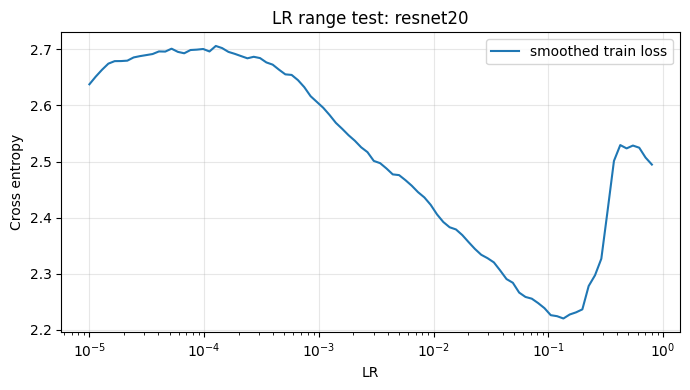

This is a diagnostic range, not a universally optimal max_lr. Files: /content/drive/MyDrive/itmo_hw2_superconvergence/runs/lr_finder_resnet20_cifar10_seed42


In [13]:
def run_lr_finder(c,lr_start=1e-5,lr_end=.8,steps=90):
    p=ROOT/'runs'/('lr_finder_'+c.model+'_'+c.dataset+'_seed'+str(c.seed));p.mkdir(parents=True,exist_ok=True)
    if (p/'COMPLETED.json').exists():
        print('SKIP LR finder:',p);return pd.read_csv(p/'history.csv')
    seed_all(c.seed)
    train,_=make_loaders(c.dataset,c.batch_size,c.seed,c.subset_size,c.workers,c.augmentation)
    model=build_model(c).to(DEVICE);model.train()
    opt=torch.optim.SGD(model.parameters(),lr=lr_start,momentum=.9,weight_decay=c.weight_decay)
    history=[];it=iter(train);smoothed=None;best=float('inf')
    for i in range(steps):
        try:x,y=next(it)
        except StopIteration:it=iter(train);x,y=next(it)
        x=x.to(DEVICE);y=y.to(DEVICE)
        lr=lr_start*(lr_end/lr_start)**(i/max(1,steps-1));opt.param_groups[0]['lr']=lr
        opt.zero_grad(set_to_none=True);loss=F.cross_entropy(model(x),y)
        if not torch.isfinite(loss):break
        loss.backward();opt.step()
        smoothed=loss.item() if smoothed is None else .95*smoothed+.05*loss.item()
        history.append({'step':i+1,'lr':lr,'loss':loss.item(),'smooth_loss':smoothed})
        if i>15 and smoothed>best*4:break
        best=min(best,smoothed)
    df=pd.DataFrame(history);df.to_csv(p/'history.csv',index=False)
    fig,ax=plt.subplots(figsize=(7,4));ax.semilogx(df.lr,df.smooth_loss,label='smoothed train loss');ax.set(xlabel='LR',ylabel='Cross entropy',title='LR range test: '+c.model);ax.grid(alpha=.3);ax.legend();fig.tight_layout()
    fig.savefig(p/'lr_range_test.png',dpi=PLT_DPI);plt.show();plt.close(fig)
    atomic_json({'steps':len(df),'min_loss_at_lr':float(df.loc[df.smooth_loss.idxmin(),'lr'])},p/'COMPLETED.json')
    print('This is a diagnostic range, not a universally optimal max_lr. Files:',p)
    return df

LR20=Exp('E03_cifar10_resnet20_lr_finder','cifar10','resnet20','triangle',1,batch_size=128,high_lr=.8)
lr20_df=run_lr_finder(LR20,lr_end=.8,steps=90)

## 7. A — 1cycle против стандартного LR
**CIFAR-10 (50k) + ResNet-20**, две модели по **16 эпох**, одинаковые конфигурации кроме расписания LR. Такое сравнение оценивает влияние расписания LR. Диапазон LR настраивается по LR finder.

In [14]:
CIFAR20_MAX_LR = 0.15  # вручную значение НЕ универсальное
FAST_EPOCHS = 16
FAST_SUBSET = 10000
COMMON20 = dict(dataset='cifar10',model='resnet20',epochs=FAST_EPOCHS,batch_size=128,seed=42,
                weight_decay=1e-4,bn_momentum=.05,augmentation=True, momentum=.9,cycle_momentum=False)
A_STANDARD = Exp(name='FAST_A_resnet20_standard16',policy='piecewise',high_lr=.1,**COMMON20)
A_CYCLE = Exp(name='FAST_A_resnet20_1cycle16',policy='onecycle',high_lr=CIFAR20_MAX_LR,
              low_lr=.01,final_lr=1e-4,**COMMON20)
EXPERIMENT_A=[A_STANDARD,A_CYCLE]
display(pd.DataFrame([asdict(x) for x in EXPERIMENT_A])[['name','epochs','policy','high_lr','weight_decay']])


,name,epochs,policy,high_lr,weight_decay
0,FAST_A_resnet20_standard16,16,piecewise,0.10,0.0001
1,FAST_A_resnet20_1cycle16,16,onecycle,0.15,0.0001


In [15]:
estimate_list(EXPERIMENT_A)

,name,steps_total,train_step_s,estimate_minutes,estimate_hours
0,FAST_A_resnet20_standard16,6256,0.0504,6.3,0.11
1,FAST_A_resnet20_1cycle16,6256,0.0995,12.0,0.20


,name,gpu,train_step_s,validation_batch_s,train_batches_per_epoch,steps_total,estimate_minutes,estimate_hours
0,FAST_A_resnet20_standard16,Tesla T4,0.0504,0.0509,391,6256,6.3,0.11
1,FAST_A_resnet20_1cycle16,Tesla T4,0.0995,0.0762,391,6256,12.0,0.20


In [16]:
result_A=run_batch(EXPERIMENT_A)

FAST_A_resnet20_standard16 epoch 1/16 | test 49.00% | best 49.00% | elapsed 0.4 min
FAST_A_resnet20_standard16 epoch 2/16 | test 63.82% | best 63.82% | elapsed 0.8 min
FAST_A_resnet20_standard16 epoch 3/16 | test 63.64% | best 63.82% | elapsed 1.3 min
FAST_A_resnet20_standard16 epoch 4/16 | test 72.01% | best 72.01% | elapsed 1.9 min
FAST_A_resnet20_standard16 epoch 5/16 | test 74.71% | best 74.71% | elapsed 2.3 min
FAST_A_resnet20_standard16 epoch 6/16 | test 74.65% | best 74.71% | elapsed 2.8 min
FAST_A_resnet20_standard16 epoch 7/16 | test 76.93% | best 76.93% | elapsed 3.2 min
FAST_A_resnet20_standard16 epoch 8/16 | test 73.21% | best 76.93% | elapsed 3.7 min
FAST_A_resnet20_standard16 epoch 9/16 | test 80.25% | best 80.25% | elapsed 4.1 min
FAST_A_resnet20_standard16 epoch 10/16 | test 78.16% | best 80.25% | elapsed 4.5 min
FAST_A_resnet20_standard16 epoch 11/16 | test 85.83% | best 85.83% | elapsed 5.0 min
FAST_A_resnet20_standard16 epoch 12/16 | test 86.47% | best 86.47% | elaps

,name,final_test_acc,best_test_acc,steps,elapsed_s
0,FAST_A_resnet20_standard16,86.77,86.90,6256,432.915146
1,FAST_A_resnet20_1cycle16,88.36,88.36,6256,421.066149


## 8. B — 1cycle при меньшем числе примеров
Выполняем **два запуска на 10k CIFAR-10**, те же ResNet-20 и 16 эпох. Сопоставляем разницу 1cycle–Standard на 10k с разницей на 50k из A. **Важно:** уменьшение набора снижает и число шагов за эпоху. Внутри каждой пары число шагов одинаковое.

In [17]:
B_STANDARD=replace(A_STANDARD,name='FAST_B_subset10k_standard16',subset_size=FAST_SUBSET)
B_CYCLE=replace(A_CYCLE,name='FAST_B_subset10k_1cycle16',subset_size=FAST_SUBSET)
EXPERIMENT_B=[B_STANDARD,B_CYCLE]

In [18]:
estimate_list(EXPERIMENT_B)

,name,steps_total,train_step_s,estimate_minutes,estimate_hours
0,FAST_B_subset10k_standard16,1264,0.085,3.2,0.05
1,FAST_B_subset10k_1cycle16,1264,0.052,2.1,0.03


,name,gpu,train_step_s,validation_batch_s,train_batches_per_epoch,steps_total,estimate_minutes,estimate_hours
0,FAST_B_subset10k_standard16,Tesla T4,0.085,0.0652,79,1264,3.2,0.05
1,FAST_B_subset10k_1cycle16,Tesla T4,0.052,0.0477,79,1264,2.1,0.03


In [19]:
result_B=run_batch(EXPERIMENT_B)

FAST_B_subset10k_standard16 epoch 1/16 | test 24.18% | best 24.18% | elapsed 0.1 min
FAST_B_subset10k_standard16 epoch 2/16 | test 40.55% | best 40.55% | elapsed 0.2 min
FAST_B_subset10k_standard16 epoch 3/16 | test 39.34% | best 40.55% | elapsed 0.4 min
FAST_B_subset10k_standard16 epoch 4/16 | test 43.11% | best 43.11% | elapsed 0.5 min
FAST_B_subset10k_standard16 epoch 5/16 | test 49.86% | best 49.86% | elapsed 0.6 min
FAST_B_subset10k_standard16 epoch 6/16 | test 46.37% | best 49.86% | elapsed 0.7 min
FAST_B_subset10k_standard16 epoch 7/16 | test 51.27% | best 51.27% | elapsed 0.9 min
FAST_B_subset10k_standard16 epoch 8/16 | test 55.83% | best 55.83% | elapsed 1.0 min
FAST_B_subset10k_standard16 epoch 9/16 | test 61.91% | best 61.91% | elapsed 1.1 min
FAST_B_subset10k_standard16 epoch 10/16 | test 60.25% | best 61.91% | elapsed 1.2 min
FAST_B_subset10k_standard16 epoch 11/16 | test 69.00% | best 69.00% | elapsed 1.4 min
FAST_B_subset10k_standard16 epoch 12/16 | test 69.59% | best 69

,name,final_test_acc,best_test_acc,steps,elapsed_s
0,FAST_B_subset10k_standard16,71.12,71.12,1264,118.936011
1,FAST_B_subset10k_1cycle16,74.66,74.66,1264,142.816518


## 9. C — эффект при большей глубине
**ResNet-56 на той же подвыборке 10k CIFAR-10**, 16 эпох.

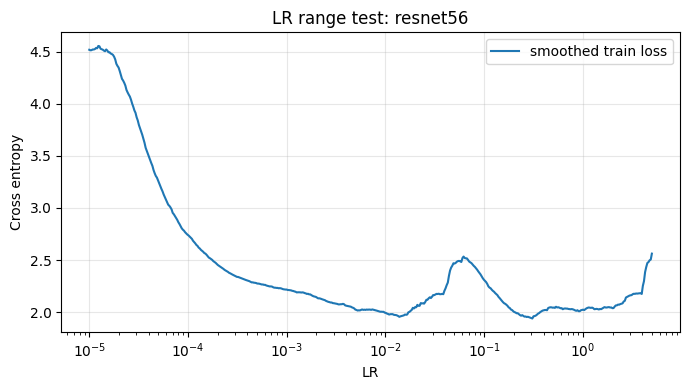

This is a diagnostic range, not a universally optimal max_lr. Files: /content/drive/MyDrive/itmo_hw2_superconvergence/runs/lr_finder_resnet56_cifar10_seed42


In [33]:
LR56=replace(LR20,name='FAST_C_resnet56_lr_finder',model='resnet56',subset_size=FAST_SUBSET)
finder56=run_lr_finder(LR56,lr_end=5.0,steps=500)

In [34]:
CIFAR56_MAX_LR = 0.3  # из предыдущей ячейки

In [35]:
COMMON56=dict(dataset='cifar10',model='resnet56',epochs=FAST_EPOCHS,batch_size=128,seed=42,
              subset_size=FAST_SUBSET,weight_decay=1e-4,bn_momentum=.05,augmentation=True,
              momentum=.9,cycle_momentum=False)
C_STANDARD=Exp(name='FAST_C_resnet56_standard16',policy='piecewise',high_lr=.1,**COMMON56)
C_CYCLE=Exp(name='FAST_C_resnet56_1cycle16',policy='onecycle',high_lr=CIFAR56_MAX_LR,
            low_lr=.01,final_lr=1e-4,**COMMON56)
EXPERIMENT_C=[C_STANDARD,C_CYCLE]


In [36]:
estimate_list(EXPERIMENT_C)

,name,steps_total,train_step_s,estimate_minutes,estimate_hours
0,FAST_C_resnet56_standard16,1264,0.1094,3.8,0.06
1,FAST_C_resnet56_1cycle16,1264,0.0949,3.0,0.05


,name,gpu,train_step_s,validation_batch_s,train_batches_per_epoch,steps_total,estimate_minutes,estimate_hours
0,FAST_C_resnet56_standard16,Tesla T4,0.1094,0.0726,79,1264,3.8,0.06
1,FAST_C_resnet56_1cycle16,Tesla T4,0.0949,0.0471,79,1264,3.0,0.05


In [37]:
result_C=run_batch(EXPERIMENT_C)

FAST_C_resnet56_standard16 epoch 1/16 | test 17.14% | best 17.14% | elapsed 0.1 min
FAST_C_resnet56_standard16 epoch 2/16 | test 20.57% | best 20.57% | elapsed 0.4 min
FAST_C_resnet56_standard16 epoch 3/16 | test 21.06% | best 21.06% | elapsed 0.6 min
FAST_C_resnet56_standard16 epoch 4/16 | test 22.53% | best 22.53% | elapsed 0.8 min
FAST_C_resnet56_standard16 epoch 5/16 | test 26.44% | best 26.44% | elapsed 1.0 min
FAST_C_resnet56_standard16 epoch 6/16 | test 27.62% | best 27.62% | elapsed 1.2 min
FAST_C_resnet56_standard16 epoch 7/16 | test 34.29% | best 34.29% | elapsed 1.4 min
FAST_C_resnet56_standard16 epoch 8/16 | test 32.22% | best 34.29% | elapsed 1.6 min
FAST_C_resnet56_standard16 epoch 9/16 | test 32.89% | best 34.29% | elapsed 1.8 min
FAST_C_resnet56_standard16 epoch 10/16 | test 38.75% | best 38.75% | elapsed 2.0 min
FAST_C_resnet56_standard16 epoch 11/16 | test 42.39% | best 42.39% | elapsed 2.2 min
FAST_C_resnet56_standard16 epoch 12/16 | test 42.84% | best 42.84% | elaps

,name,final_test_acc,best_test_acc,steps,elapsed_s
0,FAST_C_resnet56_standard16,44.17,44.17,1264,190.643414
1,FAST_C_resnet56_1cycle16,72.00,72.00,1264,184.276852


## 10. D — weight decay мешает
Используем готовый `B_CYCLE` с weight decay = 1e-4 и добавляем **только один** запуск на той же подвыборке 10k, но с weight decay = 1e-3. Это минимальная проверка эффекта регуляризации.

In [38]:
D_HIGH=replace(B_CYCLE,name='FAST_D_subset10k_1cycle_wd1e3',weight_decay=1e-3)
EXPERIMENT_D=[D_HIGH]  # WD=1e-4 уже получен на этапе B

In [39]:
estimate_list(EXPERIMENT_D)

,name,steps_total,train_step_s,estimate_minutes,estimate_hours
0,FAST_D_subset10k_1cycle_wd1e3,1264,0.0509,2.2,0.04


,name,gpu,train_step_s,validation_batch_s,train_batches_per_epoch,steps_total,estimate_minutes,estimate_hours
0,FAST_D_subset10k_1cycle_wd1e3,Tesla T4,0.0509,0.0554,79,1264,2.2,0.04


In [40]:
result_D=run_batch(EXPERIMENT_D)

FAST_D_subset10k_1cycle_wd1e3 epoch 1/16 | test 22.01% | best 22.01% | elapsed 0.1 min
FAST_D_subset10k_1cycle_wd1e3 epoch 2/16 | test 30.74% | best 30.74% | elapsed 0.2 min
FAST_D_subset10k_1cycle_wd1e3 epoch 3/16 | test 28.10% | best 30.74% | elapsed 0.4 min
FAST_D_subset10k_1cycle_wd1e3 epoch 4/16 | test 26.38% | best 30.74% | elapsed 0.5 min
FAST_D_subset10k_1cycle_wd1e3 epoch 5/16 | test 39.72% | best 39.72% | elapsed 0.6 min
FAST_D_subset10k_1cycle_wd1e3 epoch 6/16 | test 34.85% | best 39.72% | elapsed 0.7 min
FAST_D_subset10k_1cycle_wd1e3 epoch 7/16 | test 41.82% | best 41.82% | elapsed 0.9 min
FAST_D_subset10k_1cycle_wd1e3 epoch 8/16 | test 50.69% | best 50.69% | elapsed 1.0 min
FAST_D_subset10k_1cycle_wd1e3 epoch 9/16 | test 41.16% | best 50.69% | elapsed 1.1 min
FAST_D_subset10k_1cycle_wd1e3 epoch 10/16 | test 62.63% | best 62.63% | elapsed 1.2 min
FAST_D_subset10k_1cycle_wd1e3 epoch 11/16 | test 49.78% | best 62.63% | elapsed 1.4 min
FAST_D_subset10k_1cycle_wd1e3 epoch 12/16

,name,final_test_acc,best_test_acc,steps,elapsed_s
0,FAST_D_subset10k_1cycle_wd1e3,76.87,76.87,1264,120.683667


## 12. Графики и таблицы для отчёта

In [44]:
def collect_results():
    items=[]
    for j in (ROOT/'runs').glob('*/COMPLETED.json'):
        d=json.loads(j.read_text())
        if 'best_test_acc' in d:
            cfg=json.loads((j.parent/'config.json').read_text())
            d.update({k:cfg.get(k) for k in ('dataset','model','policy','epochs','batch_size','seed','subset_size','high_lr','low_lr','weight_decay')})
            items.append(d)
    df=pd.DataFrame(items)
    if len(df):df.sort_values(['dataset','model','name']).to_csv(ROOT/'exports'/'summary.csv',index=False)
    return df

def comparison_figure(names,mode='step',target=None):
    xcol={'step':'step','epoch':'epoch','time':'elapsed_s'}[mode]
    xlabel={'step':'Optimizer steps','epoch':'Epochs','time':'Elapsed time (min)'}[mode]
    fig,ax=plt.subplots(figsize=(8,4.8));records=[]
    for item in (ROOT/'runs').iterdir():
        conf=item/'config.json';hist=item/'history.csv'
        if not (conf.exists() and hist.exists()):continue
        cfg=json.loads(conf.read_text());name=cfg['name']
        if name not in names:continue
        d=pd.read_csv(hist);x=d[xcol]/60 if mode=='time' else d[xcol]
        ax.plot(x,d.test_acc,label=name)
        if target is not None:
            reached=d[d.test_acc>=target]
            if len(reached):records.append({'name':name,'target':target,'first_step':int(reached.iloc[0]['step']), 'first_time_min':round(reached.iloc[0]['elapsed_s']/60,2)})
    ax.set(xlabel=xlabel,ylabel='Test accuracy (%)',title='Own experiments — '+mode)
    if target is not None:ax.axhline(target,color='gray',ls='--',lw=1)
    ax.grid(alpha=.25);ax.legend(fontsize=8);fig.tight_layout()
    f=ROOT/'figures'/('compare_'+mode+'_'+hashlib.sha1('|'.join(names).encode()).hexdigest()[:8]+'.png')
    fig.savefig(f,dpi=PLT_DPI);plt.show();plt.close(fig)
    if records:pd.DataFrame(records).to_csv(f.with_suffix('.csv'),index=False)
    print('Saved:',f)


In [45]:
df=collect_results()
display(df[['name','final_test_acc','best_test_acc','steps','elapsed_s']] if len(df) else pd.DataFrame({'status':['No completed experiments yet']}))

,name,final_test_acc,best_test_acc,steps,elapsed_s
0,E01_mnist_lenet_standard85,99.23,99.33,39865,1264.295398
1,E02_mnist_lenet_1cycle12,99.39,99.41,5628,194.142944
2,E02b_mnist_standard12_control,99.23,99.24,5628,187.695552
3,FAST_A_resnet20_standard16,86.77,86.90,6256,432.915146
4,FAST_A_resnet20_1cycle16,88.36,88.36,6256,421.066149
5,FAST_B_subset10k_standard16,71.12,71.12,1264,118.936011
6,FAST_B_subset10k_1cycle16,74.66,74.66,1264,142.816518
7,FAST_C_resnet56_standard16,44.17,44.17,1264,190.643414
8,FAST_C_resnet56_1cycle16,72.00,72.00,1264,184.276852
9,FAST_D_subset10k_1cycle_wd1e3,76.87,76.87,1264,120.683667


In [43]:

def report_key_figures():
    groups = {
      'A_full_resnet20': [A_STANDARD.name,A_CYCLE.name],
      'B_subset10k_resnet20': [B_STANDARD.name,B_CYCLE.name],
      'C_subset10k_resnet56': [C_STANDARD.name,C_CYCLE.name],
      'D_weight_decay_subset10k': [B_CYCLE.name,D_HIGH.name],
      'MNIST': [c.name for c in STAGE1],
    }
    for title,names in groups.items():
        print('Plot group:',title)
        for mode in ('epoch','step','time'):
            comparison_figure(names,mode=mode)


Plot group: A_full_resnet20


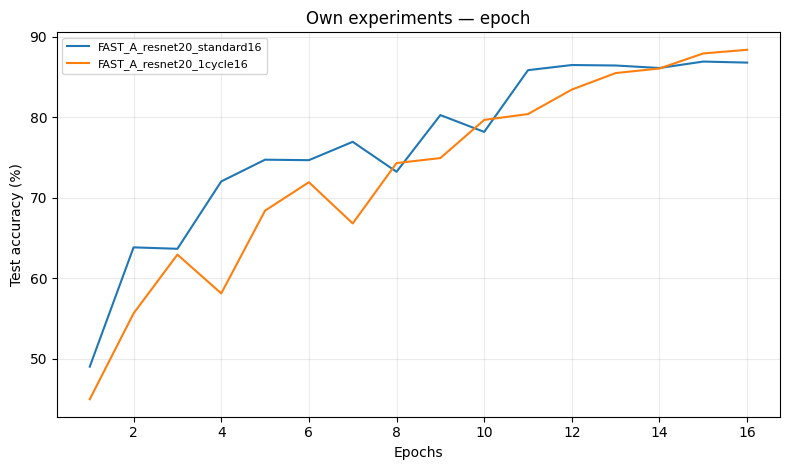

Saved: /content/drive/MyDrive/itmo_hw2_superconvergence/figures/compare_epoch_4dfa1311.png


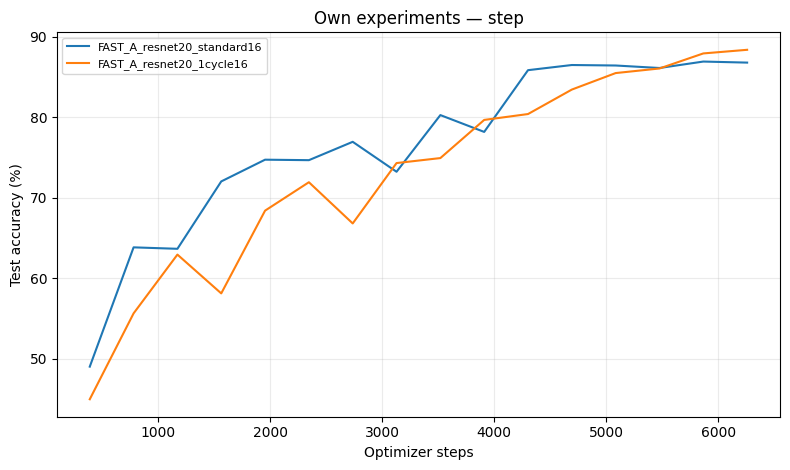

Saved: /content/drive/MyDrive/itmo_hw2_superconvergence/figures/compare_step_4dfa1311.png


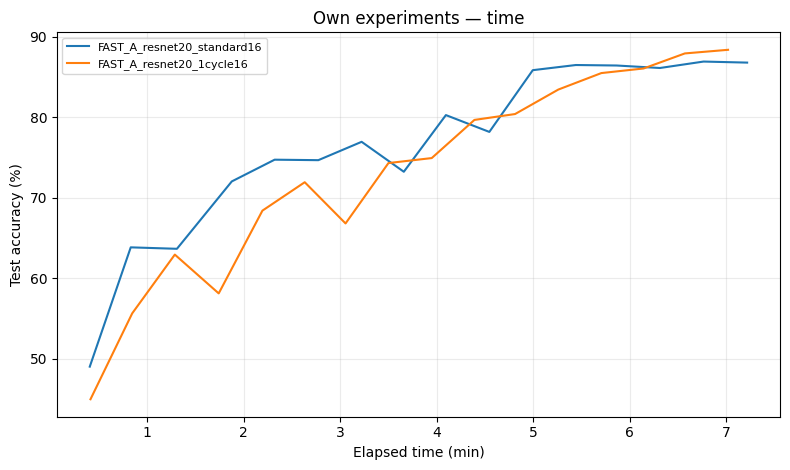

Saved: /content/drive/MyDrive/itmo_hw2_superconvergence/figures/compare_time_4dfa1311.png
Plot group: B_subset10k_resnet20


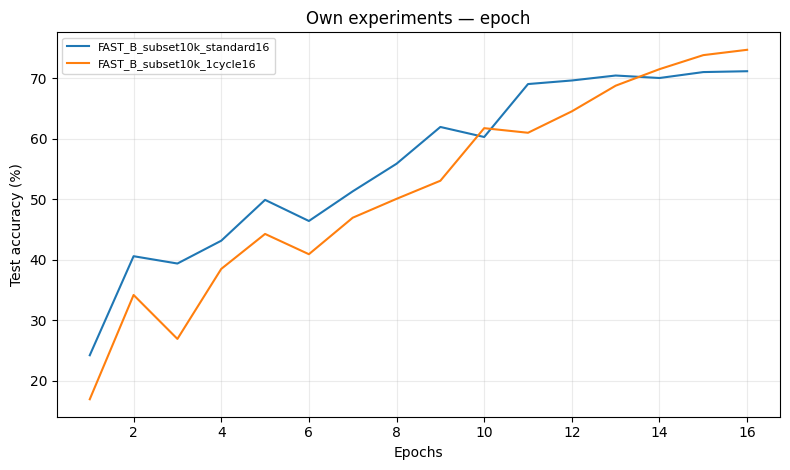

Saved: /content/drive/MyDrive/itmo_hw2_superconvergence/figures/compare_epoch_db4ec4b1.png


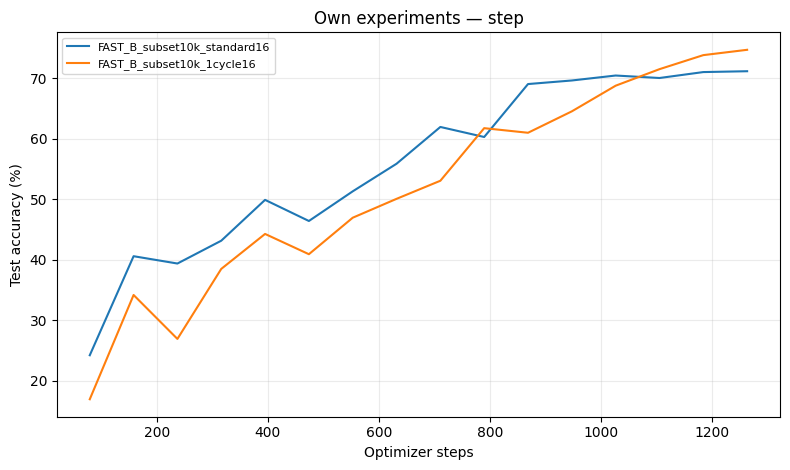

Saved: /content/drive/MyDrive/itmo_hw2_superconvergence/figures/compare_step_db4ec4b1.png


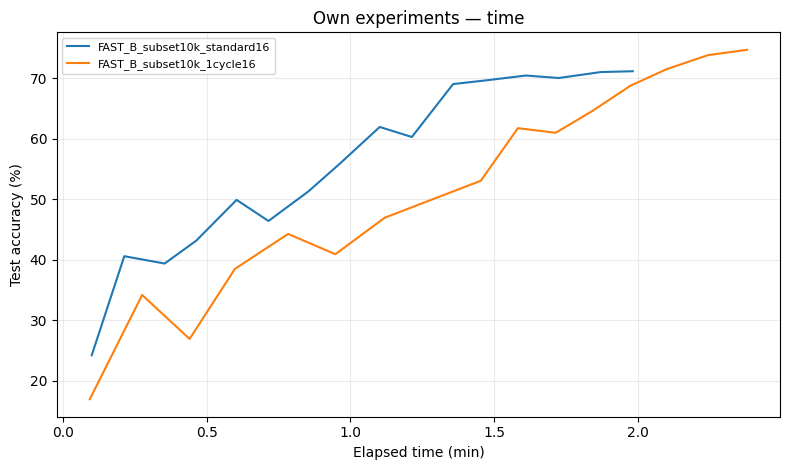

Saved: /content/drive/MyDrive/itmo_hw2_superconvergence/figures/compare_time_db4ec4b1.png
Plot group: C_subset10k_resnet56


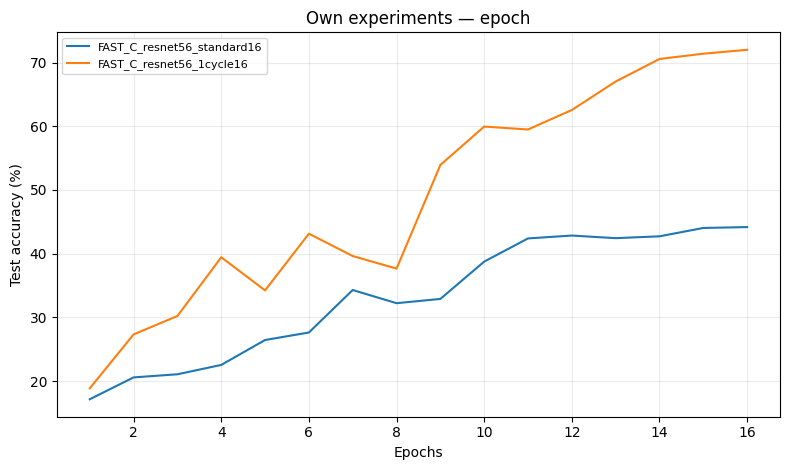

Saved: /content/drive/MyDrive/itmo_hw2_superconvergence/figures/compare_epoch_d325f990.png


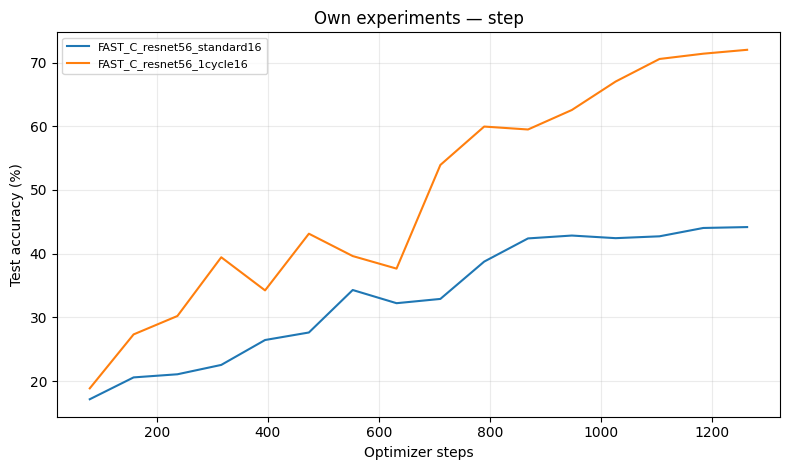

Saved: /content/drive/MyDrive/itmo_hw2_superconvergence/figures/compare_step_d325f990.png


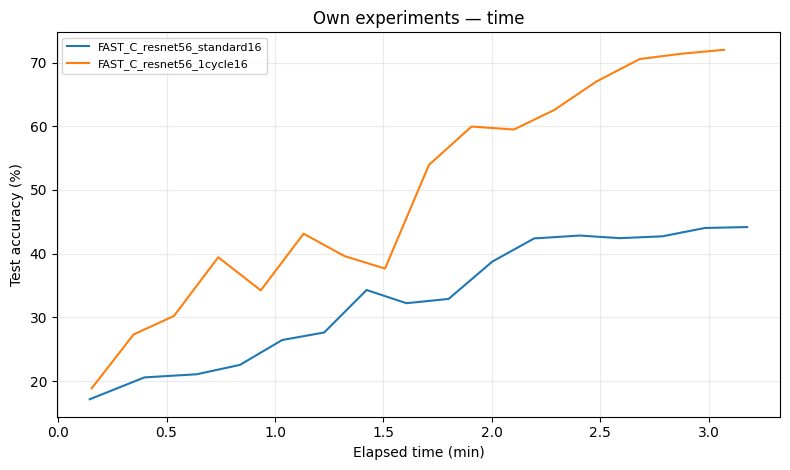

Saved: /content/drive/MyDrive/itmo_hw2_superconvergence/figures/compare_time_d325f990.png
Plot group: D_weight_decay_subset10k


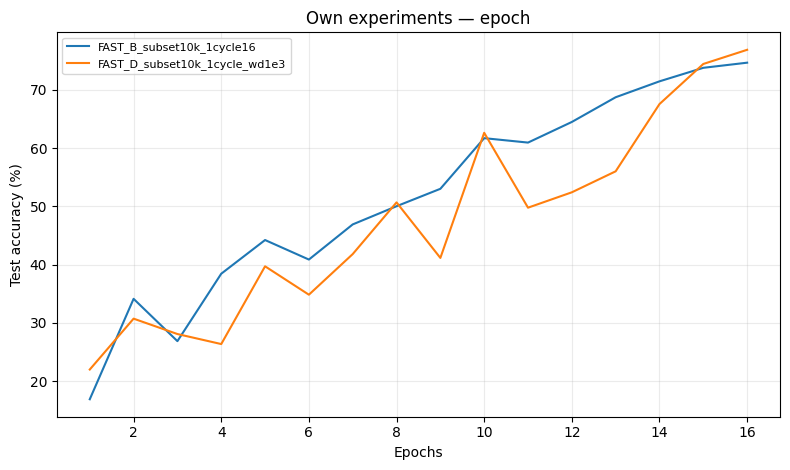

Saved: /content/drive/MyDrive/itmo_hw2_superconvergence/figures/compare_epoch_dcc8d2b5.png


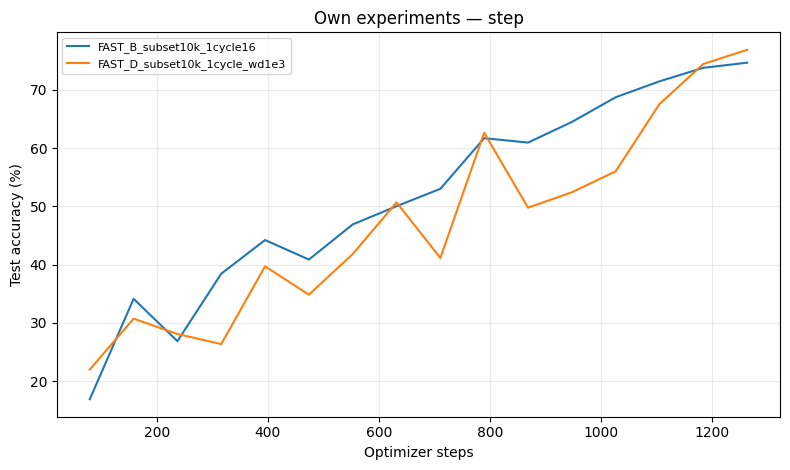

Saved: /content/drive/MyDrive/itmo_hw2_superconvergence/figures/compare_step_dcc8d2b5.png


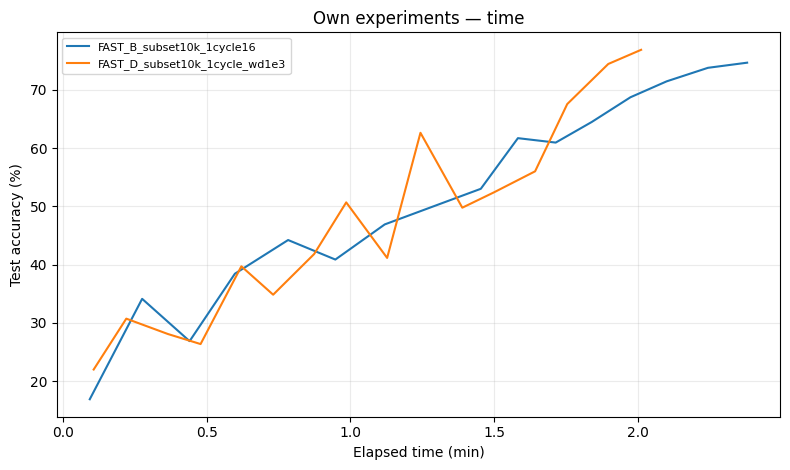

Saved: /content/drive/MyDrive/itmo_hw2_superconvergence/figures/compare_time_dcc8d2b5.png
Plot group: MNIST


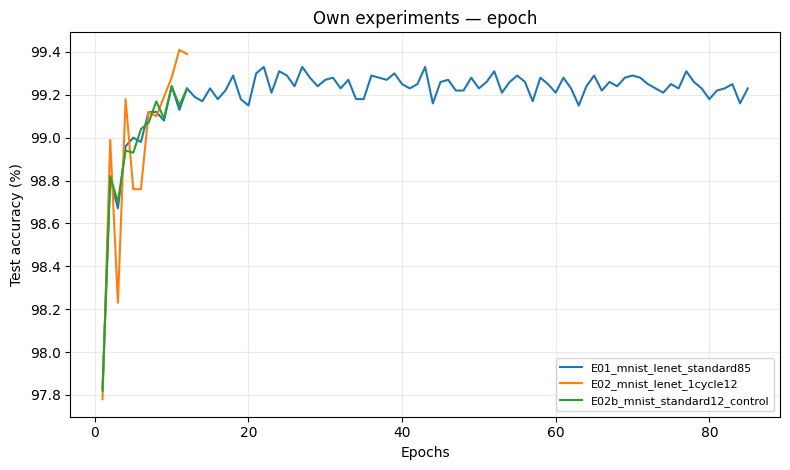

Saved: /content/drive/MyDrive/itmo_hw2_superconvergence/figures/compare_epoch_68fb1140.png


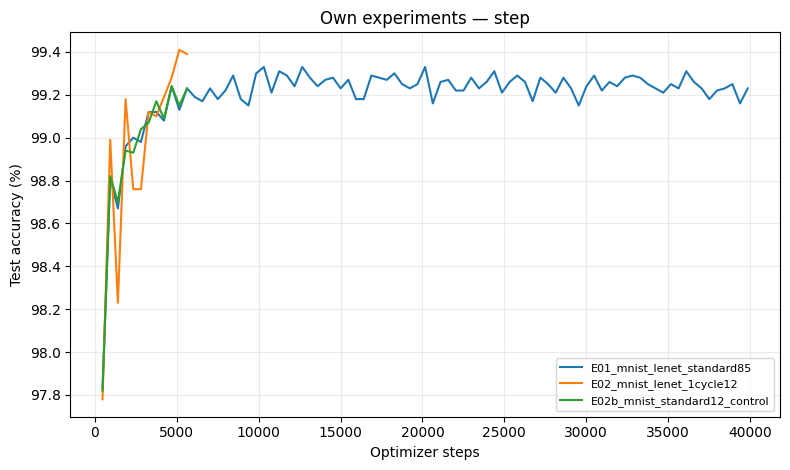

Saved: /content/drive/MyDrive/itmo_hw2_superconvergence/figures/compare_step_68fb1140.png


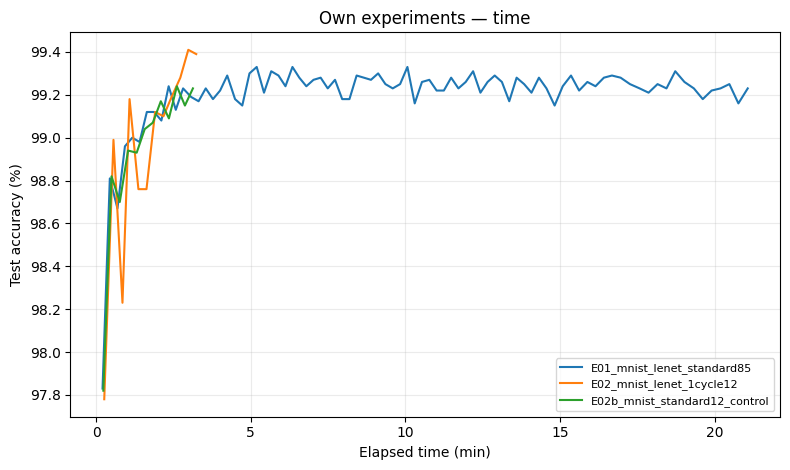

Saved: /content/drive/MyDrive/itmo_hw2_superconvergence/figures/compare_time_68fb1140.png


In [46]:
report_key_figures()

In [47]:
def report_hypotheses_bc():
    out = ROOT / "figures" / "hypotheses_BC"
    out.mkdir(parents=True, exist_ok=True)

    configs = {
        "A_standard": A_STANDARD,
        "A_cycle": A_CYCLE,
        "B_standard": B_STANDARD,
        "B_cycle": B_CYCLE,
        "C_standard": C_STANDARD,
        "C_cycle": C_CYCLE,
    }
    results = {}

    for key, config in configs.items():
        path = runpath(config)

        if not (path / "COMPLETED.json").exists():
            raise FileNotFoundError(
                f"Эксперимент {config.name} ещё не завершён: {path}"
            )

        history = pd.read_csv(path / "history.csv")

        results[key] = {
            "config": config,
            "history": history,
            "final_acc": float(history.test_acc.iloc[-1]),
            "best_acc": float(history.test_acc.max()),
        }

    b_rows = []

    for size, standard, cycle in [
        (50000, "A_standard", "A_cycle"),
        (10000, "B_standard", "B_cycle"),
    ]:
        std = results[standard]["final_acc"]
        cyc = results[cycle]["final_acc"]

        b_rows.append({
            "train_samples": size,
            "standard_acc": std,
            "onecycle_acc": cyc,
            "delta_pp": cyc - std,
        })

    df_b = pd.DataFrame(b_rows)
    df_b.to_csv(out / "B_data_size_results.csv", index=False)

    fig, ax = plt.subplots(figsize=(7, 4.5))

    x = np.arange(len(df_b))
    width = 0.34

    ax.bar(
        x - width / 2,
        df_b.standard_acc,
        width,
        label="Standard",
    )

    ax.bar(
        x + width / 2,
        df_b.onecycle_acc,
        width,
        label="1cycle",
    )

    ax.set_xticks(x)
    ax.set_xticklabels(["50k samples", "10k samples"])
    ax.set_ylabel("Final test accuracy (%)")
    ax.set_title("B — Effect of training set size")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)

    for i, row in df_b.iterrows():
        ax.annotate(
            f"Δ = {row.delta_pp:+.2f} pp",
            (i, max(row.standard_acc, row.onecycle_acc)),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            fontsize=10,
        )

    ax.set_ylim(
        0,
        min(100, max(df_b.standard_acc.max(),
                     df_b.onecycle_acc.max()) + 12)
    )

    fig.tight_layout()
    fig.savefig(
        out / "B_data_size_comparison.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    c_rows = []

    for model, standard, cycle in [
        ("ResNet-20", "B_standard", "B_cycle"),
        ("ResNet-56", "C_standard", "C_cycle"),
    ]:
        std = results[standard]["final_acc"]
        cyc = results[cycle]["final_acc"]

        c_rows.append({
            "model": model,
            "standard_acc": std,
            "onecycle_acc": cyc,
            "delta_pp": cyc - std,
        })

    df_c = pd.DataFrame(c_rows)
    df_c.to_csv(out / "C_depth_results.csv", index=False)

    fig, ax = plt.subplots(figsize=(7, 4.5))

    x = np.arange(len(df_c))

    ax.bar(
        x - width / 2,
        df_c.standard_acc,
        width,
        label="Standard",
    )

    ax.bar(
        x + width / 2,
        df_c.onecycle_acc,
        width,
        label="1cycle",
    )

    ax.set_xticks(x)
    ax.set_xticklabels(df_c.model)
    ax.set_ylabel("Final test accuracy (%)")
    ax.set_title("C — Effect of network depth (10k samples)")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)

    for i, row in df_c.iterrows():
        ax.annotate(
            f"Δ = {row.delta_pp:+.2f} pp",
            (i, max(row.standard_acc, row.onecycle_acc)),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            fontsize=10,
        )

    ax.set_ylim(
        0,
        min(100, max(df_c.standard_acc.max(),
                     df_c.onecycle_acc.max()) + 12)
    )

    fig.tight_layout()
    fig.savefig(
        out / "C_depth_comparison.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    groups = {
        "B_full_50k": ["A_standard", "A_cycle"],
        "B_subset_10k": ["B_standard", "B_cycle"],
        "C_resnet20_10k": ["B_standard", "B_cycle"],
        "C_resnet56_10k": ["C_standard", "C_cycle"],
    }

    for name, keys in groups.items():
        fig, ax = plt.subplots(figsize=(7, 4.5))

        for key in keys:
            item = results[key]
            h = item["history"]

            label = (
                "1cycle"
                if item["config"].policy == "onecycle"
                else "Standard"
            )

            ax.plot(
                h.epoch,
                h.test_acc,
                marker=".",
                label=label,
            )

        ax.set(
            xlabel="Epoch",
            ylabel="Test accuracy (%)",
            title=name.replace("_", " "),
        )
        ax.legend()
        ax.grid(alpha=0.25)

        fig.tight_layout()
        fig.savefig(
            out / f"{name}_curves.png",
            dpi=200,
            bbox_inches="tight",
        )
        plt.close(fig)

    print("\nГипотеза B:")
    display(df_b)

    print("\nГипотеза C:")
    display(df_c)

    print("\nВсе графики и таблицы сохранены в:")
    print(out)

    return df_b, df_c

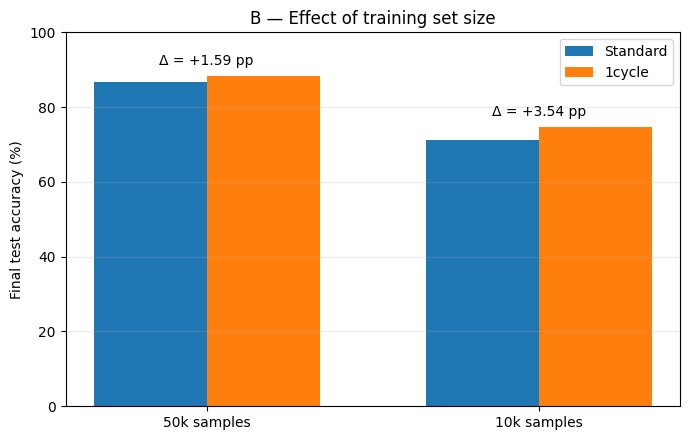

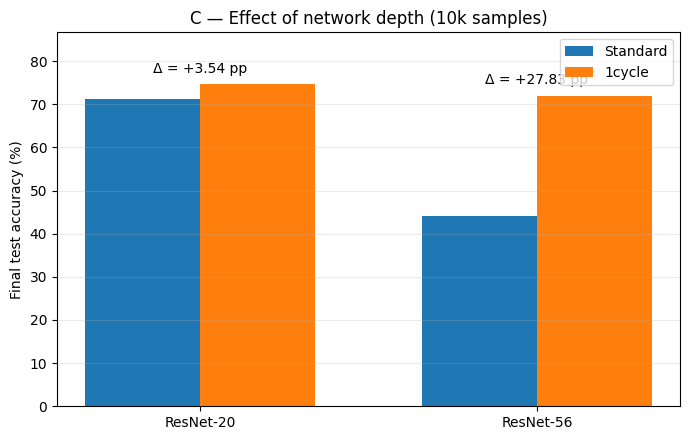


Гипотеза B:


,train_samples,standard_acc,onecycle_acc,delta_pp
0,50000,86.77,88.36,1.59
1,10000,71.12,74.66,3.54



Гипотеза C:


,model,standard_acc,onecycle_acc,delta_pp
0,ResNet-20,71.12,74.66,3.54
1,ResNet-56,44.17,72.00,27.83



Все графики и таблицы сохранены в:
/content/drive/MyDrive/itmo_hw2_superconvergence/figures/hypotheses_BC


In [48]:
df_b, df_c = report_hypotheses_bc()

## 13. Экспорт для GitHub / отчёта

In [49]:
def make_report_bundle():
    collect_results()
    base=ROOT/'exports'/'hw2_superconvergence_report_artifacts'
    if base.exists():shutil.rmtree(base)
    base.mkdir(parents=True)
    for source in [ROOT/'environment.json',ROOT/'exports'/'summary.csv']:
        if source.exists():shutil.copy2(source,base/source.name)
    for p in (ROOT/'runs').iterdir():
        if not p.is_dir():continue
        dest=base/p.name;dest.mkdir()
        for name in ('config.json','metrics.json','history.csv','lr_history.csv','lr_range_test.png','COMPLETED.json'):
            if (p/name).exists():shutil.copy2(p/name,dest/name)
        if (p/'figures').exists():shutil.copytree(p/'figures',dest/'figures')
    if (ROOT/'figures').exists():shutil.copytree(ROOT/'figures',base/'comparisons',dirs_exist_ok=True)
    archive=shutil.make_archive(str(base),'zip',root_dir=base)
    print('Archive:',archive);return archive


In [50]:
make_report_bundle()

Archive: /content/drive/MyDrive/itmo_hw2_superconvergence/exports/hw2_superconvergence_report_artifacts.zip


'/content/drive/MyDrive/itmo_hw2_superconvergence/exports/hw2_superconvergence_report_artifacts.zip'